# comparation ldp

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

## Comparação utilidade–privacidade

PR-AUC local é principal; global, recall e FAR são complementares. A comparação **clipping vs sem LDP** mede a alteração por recorte. A comparação **LDP vs clipping do mesmo perfil** mede o efeito adicional do ruído e do seu feedback nas rondas seguintes.

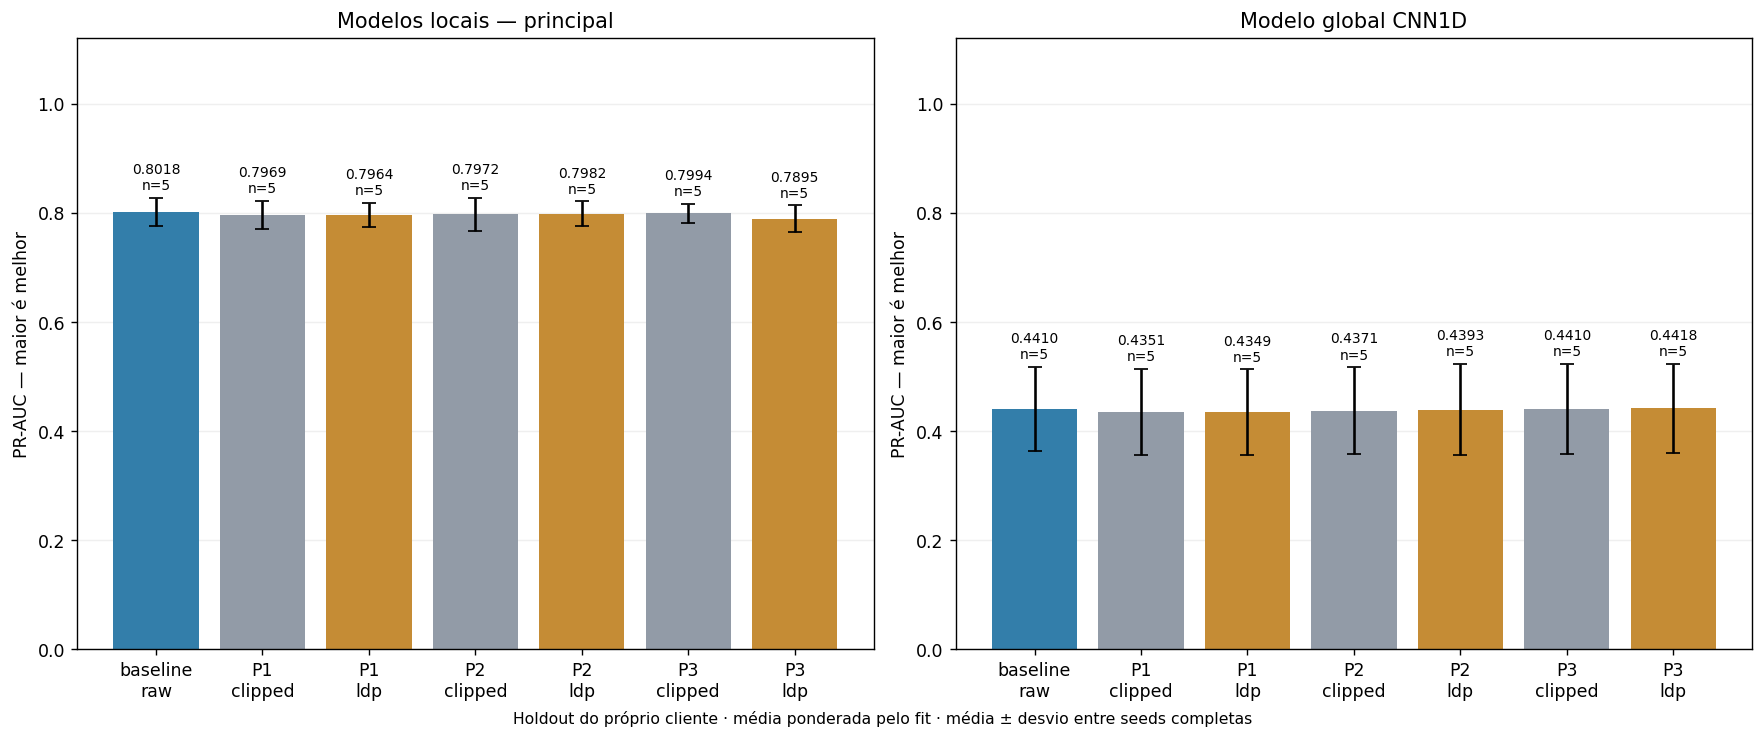

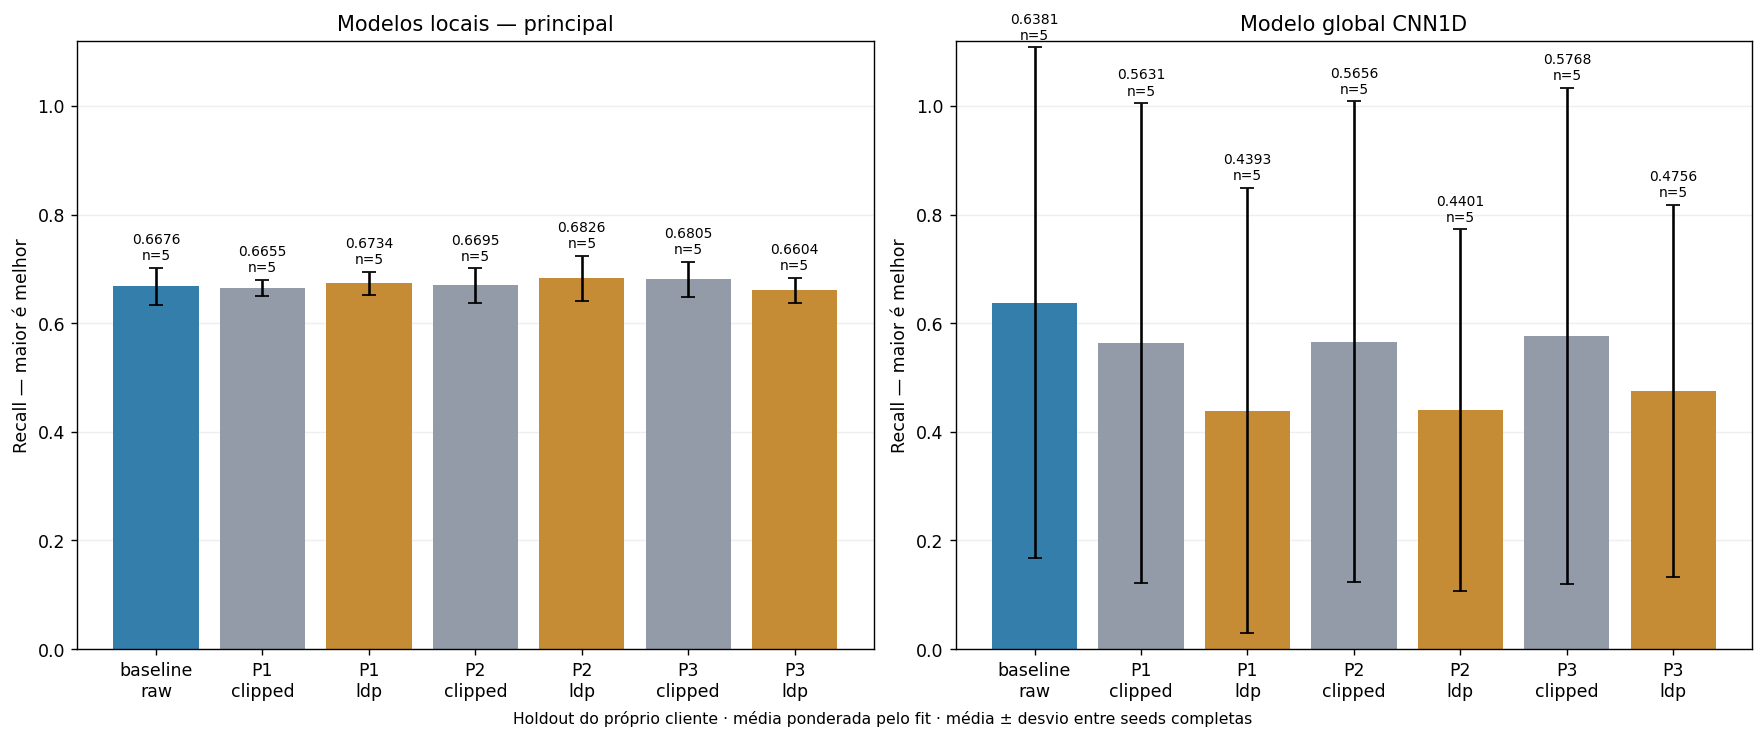

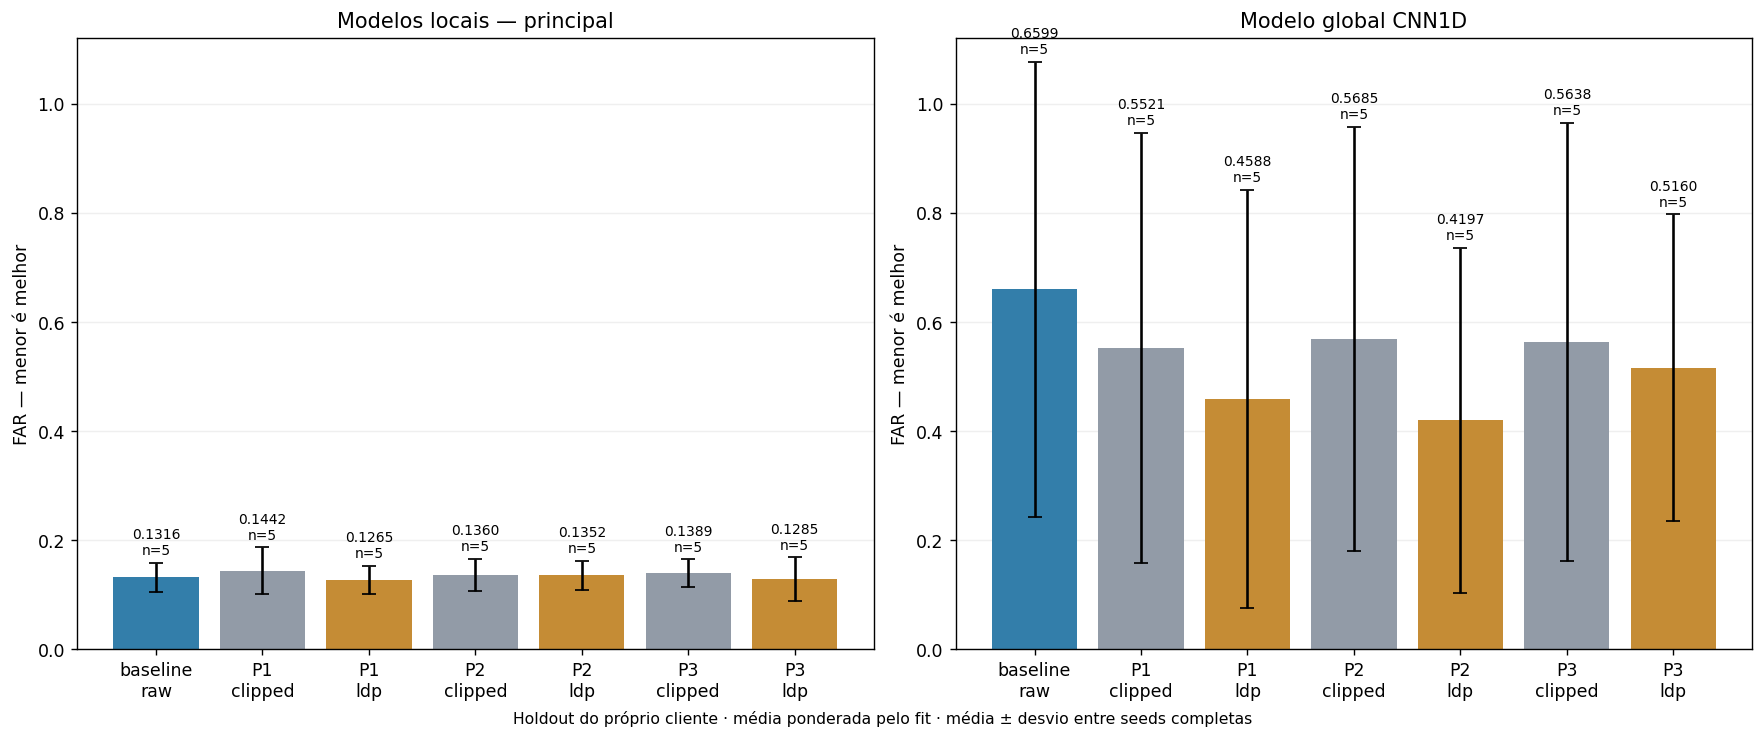

,profile,role,metric,paired_seeds,LDP_minus_clipping,std_delta
0,P1,local,pr_auc_ap,5,-0.000473,0.010726
1,P1,global,pr_auc_ap,5,-0.000235,0.004221
2,P2,local,pr_auc_ap,5,0.001059,0.013804
3,P2,global,pr_auc_ap,5,0.002272,0.019622
4,P3,local,pr_auc_ap,5,-0.009964,0.009227
5,P3,global,pr_auc_ap,5,0.000789,0.006666
6,P1,local,recall,5,0.007892,0.020632
7,P1,global,recall,5,-0.123826,0.349963
8,P2,local,recall,5,0.013112,0.022142
9,P2,global,recall,5,-0.125549,0.357388


### Como interpretar a proteção

O clipping é conjunto sobre toda a mensagem do cliente e a sensibilidade de substituição é 2C. O ruído do treino usa mecanismos da diffprivlib com aleatoriedade segura, independente das seeds de treino. Só a mensagem já perturbada e convertida em probabilidades entra na lista de contribuições para agregação; esta continua a ser uma simulação num processo, sem isolamento real dos clientes. O registo de orçamento cobra cada divulgação antes da randomização, incluindo tentativas interrompidas. **ε=4 é por uma execução completa de um cliente, não pela grelha inteira.** As 15 execuções privadas planeadas por cliente somam conservadoramente ε=60 se todas forem divulgadas; delta também se compõe nos perfis Gaussianos. A presença de referências e controlos não privados impede apresentar a experiência inteira como uma divulgação ε=4-LDP.

**Limite do âmbito:** os dados e transformações preparados são fixados. A normalização histórica usa estatísticas agregadas do fit; não foi demonstrada privacidade end-to-end para a substituição dos dados ECG brutos de um cliente. A seleção de C, métricas de avaliação, checkpoints e dados originais já divulgados não são automaticamente protegidos. Os notebooks são resultados de investigação; não são um pacote de resultados DP para publicação de dados clínicos confidenciais.

Todas as condições foram concluídas. Comparar primeiro as diferenças pareadas e a variabilidade; selecionar pelo desempenho local e compromisso de privacidade, sem tratar a escolha exploratória como avaliação final independente.

In [1]:
from support.ldp_logits.notebooks import render_comparison
render_comparison()

## Gráfico final de privacidade–utilidade

## Síntese: compromisso entre proteção e utilidade

PR-AUC no holdout do próprio cliente, ponderado pelo fit, na terceira ronda fixa. Pontos: média; barras: desvio-padrão entre seeds. São categorias de proteção, **não uma escala numérica de privacidade**. Todos os perfis privados usam ε=4 por ciclo de cliente.

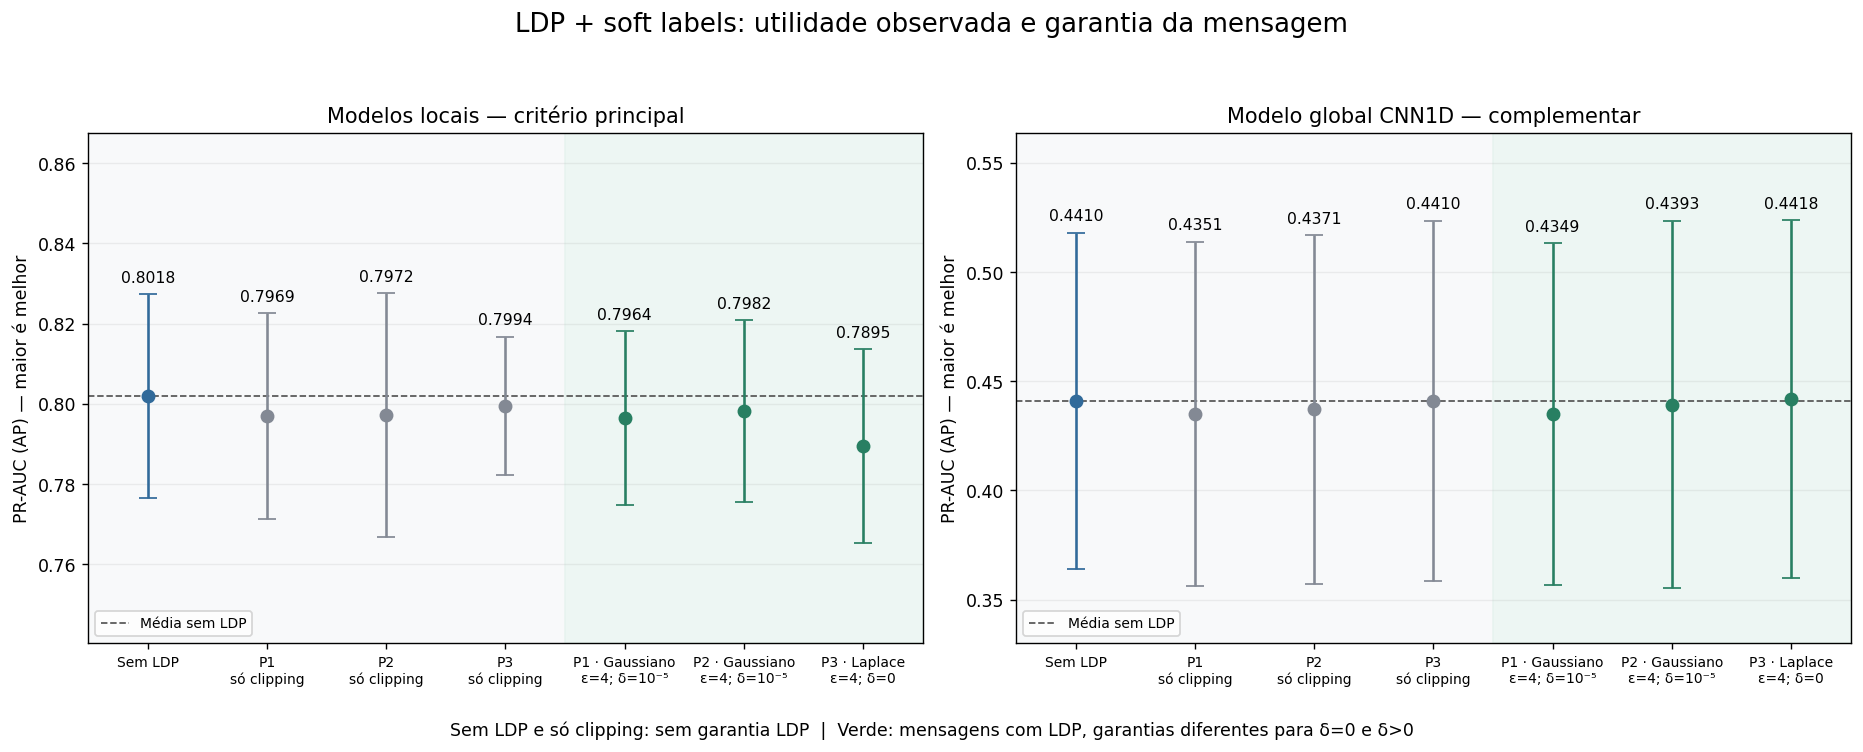

,perfil,PR_AUC_local,diferenca_face_sem_LDP,diferenca_face_so_clipping
0,P1_ldp,0.796416,-0.005418,-0.000473
1,P2_ldp,0.798223,-0.003610,0.001059
2,P3_ldp,0.789456,-0.012377,-0.009964


**Leitura:** compare cada perfil privado com o respetivo controlo de clipping e com a referência sem LDP. A proximidade do PR-AUC indica preservação de utilidade nesta avaliação; não prova equivalência estatística. As escalas verticais dos dois painéis diferem para tornar a variação visível. P1: logits originais/C=0,5; P2: margem/C=0,5; P3: margem/C=2. Não se pode concluir qual ε oferece o melhor compromisso, pois só ε=4 foi treinado. ε=4 refere-se a um ciclo, não à grelha inteira; a garantia é da mensagem preparada, não de todo o processamento dos ECG nem das métricas divulgadas.

### Leitura do gráfico e escolha segundo a aplicação

**Utilidade local.** A referência sem LDP apresenta PR-AUC=0.8018. Com proteção, P2 obtém 0.7982, P1 0.7964 e P3 0.7895. Face à referência, as diferenças são -0.0036, -0.0054 e -0.0124, respetivamente. São diferenças absolutas de PR-AUC, não percentagens. P1 e P2 preservam melhor a média local do que P3 nesta experiência. As barras representam desvio entre seeds, não intervalos de confiança; o gráfico não demonstra superioridade estatística nem equivalência.

**Efeito adicional do ruído.** Comparando com o controlo de clipping do mesmo perfil, o PR-AUC local muda -0.0005 em P1, +0.0011 em P2 e -0.0100 em P3. A pequena melhoria média de P2 não prova que o ruído melhora o modelo. O resultado de P3 indica maior perda média local neste perfil específico; não permite concluir que Laplace é sempre pior, pois também mudam a norma e C.

**Modelo global.** P3 tem a maior média entre os perfis privados (0.4418), próxima da referência (0.4410). Isto não compensa automaticamente a perda local: neste projeto, o critério principal é o PR-AUC dos modelos dos próprios clientes.

**Se a aplicação privilegia deteção local em wearables:** P2 é a candidata exploratória mais favorável pelo PR-AUC local médio entre os perfis privados. Apresenta também recall local=0.6826, com FAR=0.1352. O gráfico não mede autonomia, memória ou latência no wearable; esses custos exigem testes próprios.

**Se a prioridade é reduzir falsos alarmes:** P1 merece comparação com P2, pois apresenta FAR local=0.1265, contra 0.1352 de P2, com recall 0.6734 contra 0.6826. Estes valores vêm das tabelas de métricas e usam a decisão fixa argmax/0,5. A escolha clínica exige definir o custo de falhar anomalias e o de gerar alarmes, e validar o limiar num conjunto próprio.

**Se o requisito de privacidade exige δ=0:** P3 é o único dos três perfis privados testados que satisfaz esse requisito, com Laplace e ε=4, aceitando a menor média local observada. P1 e P2 usam ε=4 e δ=10⁻⁵. Este requisito mais estrito em δ não estabelece uma ordenação universal de segurança entre as implementações. Sem LDP e só clipping são referências de utilidade, não alternativas que satisfaçam um requisito LDP.

**Orientação para este projeto:** levar P2 como candidata principal quando se aceita (ε=4, δ=10⁻⁵) e se privilegia PR-AUC local; manter P1 como alternativa se a redução de falsos alarmes for prioritária; considerar P3 se δ=0 for obrigatório. A decisão é exploratória nas mesmas cinco seeds: falta validação independente e o gráfico não permite escolher outro ε. Uma pequena perda de PR-AUC não demonstra resistência a ataques. As garantias referem-se às mensagens preparadas e ao orçamento por ciclo, sem proteger automaticamente métricas, checkpoints ou todo o processamento dos ECG.

In [2]:
from support.ldp_logits.notebooks import render_privacy_utility_summary
render_privacy_utility_summary()